# AI 08: Регрессия стоимости автомобилей с использованием Decision Tree (Дерево решений)
## Домашнее задание AI 08 — Решение №1 (Decision Tree Regressor)

### 1. Теоретические основы алгоритма Decision Tree (Дерево решений)

**Decision Tree (Дерево решений)** — это непараметрический алгоритм контролируемого машинного обучения, который разбивает пространство признаков на непересекающиеся гиперпрямоугольные области с помощью последовательности решающих правил вида $[x_j \le s]$.

#### Принцип работы в задаче регрессии:
1. **Жадное рекурсивное бинарное разбиение (Recursive Binary Splitting):**
   На каждом узле алгоритм ищет признак $j$ и порог разбиения $s$, которые максимально снижают среднеквадратичную ошибку (MSE):
   $$\min_{j, s} \left[ \sum_{i \in R_1(j, s)} (y_i - \hat{y}_{R_1})^2 + \sum_{i \in R_2(j, s)} (y_i - \hat{y}_{R_2})^2 ight]$$
   где $R_1(j, s) = \{X | X_j \le s\}$ и $R_2(j, s) = \{X | X_j > s\}$, а прогноз $\hat{y}_{R_m}$ равен выборочному среднему целевой переменной в области $R_m$.
2. **Прогноз модели:**
   Для нового объекта прогноз определяется как константа листа, в который попал объект:
   $$\hat{y}(x) = rac{1}{|R_m|} \sum_{i \in R_m} y_i$$
3. **Проблема переобучения (High Variance):**
   Неограниченное дерево способно идеально запомнить обучающую выборку ($R^2_{	ext{train}} pprox 1.0$), создавая листья с одним примером. Для регуляризации используются ключевые гиперпараметры:
   - `max_depth` — максимальная глубина дерева.
   - `min_samples_split` — минимальное число объектов для разбиения узла.
   - `min_samples_leaf` — минимальное число объектов в листе.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline

### 2. Загрузка и первичный анализ датасета `Used_Cars_Homework.csv`

In [4]:
FILE_PATH = 'Used_Cars_Homework.csv'
data = pd.read_csv(FILE_PATH)

# Добавляем созданный в AI 07 признак среднегодового пробега
data['mileage_per_year'] = data['mileage_km'] / data['age_years']

print(f"Размер датасета: {data.shape[0]} строк, {data.shape[1]} столбцов")
data.head()

Размер датасета: 300 строк, 10 столбцов


In [5]:
data.tail()

In [6]:
data.sample(3, random_state=42)

In [7]:
data.dtypes

In [8]:
data.isna().sum()

In [9]:
data.describe()

### 3. Разделение признаков, препроцессинг и разбиение на выборки

В древовидных алгоритмах масштабирование числовых признаков (`StandardScaler` или `MinMaxScaler`) не требуется, так как разбиения зависят только от монотонного порядка значений признака.
Для категориальных признаков используем `OneHotEncoder`.

In [11]:
target_col = 'price_azn'
y = data[target_col].values
X = data.drop(columns=[target_col])

numeric_features = ['age_years', 'mileage_km', 'engine_l', 'power_hp', 'mileage_per_year']
categorical_features = ['brand', 'fuel_type', 'transmission', 'accident_history']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Обучающая выборка: {X_train.shape[0]} объектов")
print(f"Тестовая выборка  : {X_test.shape[0]} объектов")

Обучающая выборка: 240 объектов
Тестовая выборка  : 60 объектов


### 4. Обучение DecisionTreeRegressor и подбор гиперпараметров через GridSearchCV

Настраиваем ключевые регуляризационные параметры дерева: `max_depth`, `min_samples_split`, `min_samples_leaf` с 5-кратной кросс-валидацией (`KFold(shuffle=True)`).

In [13]:
reg = DecisionTreeRegressor(random_state=42, criterion='squared_error')

pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('tree', reg)
])

param_grid = {
    'tree__max_depth': [3, 5, 7, 10, None],
    'tree__min_samples_split': [2, 5, 10],
    'tree__min_samples_leaf': [1, 3, 5, 10],
}

cv = KFold(n_splits=5, random_state=42, shuffle=True)
grid_search = GridSearchCV(pipe, param_grid, cv=cv, scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("Лучшие гиперпараметры:")
for param, val in grid_search.best_params_.items():
    print(f"  • {param}: {val}")

Лучшие гиперпараметры:
  • tree__max_depth: 7
  • tree__min_samples_leaf: 10
  • tree__min_samples_split: 2


### 5. Оценка качества модели на обучающей и тестовой выборках

In [15]:
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = rmse(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = rmse(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("=" * 55)
print("             МЕТРИКИ КАЧЕСТВА DECISION TREE")
print("=" * 55)
print(f"Train R2   : {train_r2:.4f}  |  Test R2   : {test_r2:.4f}")
print(f"Train RMSE : {train_rmse:.2f} AZN |  Test RMSE : {test_rmse:.2f} AZN")
print(f"Train MAE  : {train_mae:.2f} AZN |  Test MAE  : {test_mae:.2f} AZN")
print(f"Разрыв переобучения (Train R2 - Test R2): {train_r2 - test_r2:.4f}")
print("=" * 55)

             МЕТРИКИ КАЧЕСТВА DECISION TREE
Train R2   : 0.7884  |  Test R2   : 0.7288
Train RMSE : 4445.85 AZN |  Test RMSE : 5265.97 AZN
Train MAE  : 3500.62 AZN |  Test MAE  : 4220.31 AZN
Разрыв переобучения (Train R2 - Test R2): 0.0597


### 6. Визуализация: Реальные значения vs Прогнозные и Важность признаков

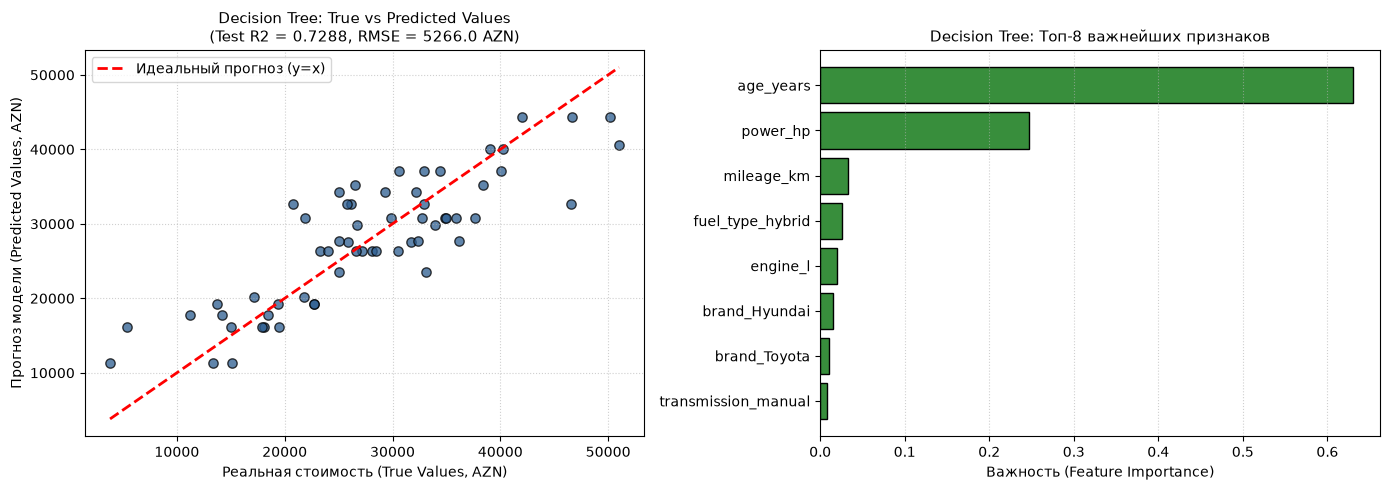

In [17]:
# Извлечение важности признаков
prep_step = best_model.named_steps['preprocessor']
feat_names = prep_step.get_feature_names_out()
clean_names = [f.replace('num__', '').replace('cat__', '') for f in feat_names]
tree_step = best_model.named_steps['tree']
importances = tree_step.feature_importances_

feat_imp_df = pd.DataFrame({'Feature': clean_names, 'Importance': importances}).sort_values('Importance', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Scatter True vs Pred
axes[0].scatter(y_test, y_test_pred, color='#2b5c8f', alpha=0.75, edgecolors='k', s=45)
min_v = min(y_test.min(), y_test_pred.min())
max_v = max(y_test.max(), y_test_pred.max())
axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', lw=2, label='Идеальный прогноз (y=x)')
axes[0].set_title(f'Decision Tree: True vs Predicted Values\n(Test R2 = {test_r2:.4f}, RMSE = {test_rmse:.1f} AZN)', fontsize=11)
axes[0].set_xlabel('Реальная стоимость (True Values, AZN)')
axes[0].set_ylabel('Прогноз модели (Predicted Values, AZN)')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

# 2. Feature Importance
top_feats = feat_imp_df.head(8).sort_values('Importance', ascending=True)
axes[1].barh(top_feats['Feature'], top_feats['Importance'], color='#388e3c', edgecolor='black')
axes[1].set_title('Decision Tree: Топ-8 важнейших признаков', fontsize=11)
axes[1].set_xlabel('Важность (Feature Importance)')
axes[1].grid(True, axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 7. Прогнозирование стоимости для 3 новых автомобилей (из AI 07)

In [19]:
new_cars = pd.DataFrame([
    {'brand': 'Toyota', 'age_years': 5, 'mileage_km': 75000, 'engine_l': 1.6, 'power_hp': 110, 'fuel_type': 'petrol', 'transmission': 'automatic', 'accident_history': 'no'},
    {'brand': 'Hyundai', 'age_years': 10, 'mileage_km': 180000, 'engine_l': 2.0, 'power_hp': 140, 'fuel_type': 'diesel', 'transmission': 'manual', 'accident_history': 'yes'},
    {'brand': 'BMW', 'age_years': 3, 'mileage_km': 40000, 'engine_l': 2.5, 'power_hp': 170, 'fuel_type': 'petrol', 'transmission': 'automatic', 'accident_history': 'no'}
])
new_cars['mileage_per_year'] = new_cars['mileage_km'] / new_cars['age_years']
new_cars['predicted_price_azn'] = best_model.predict(new_cars)

for i, row in new_cars.iterrows():
    print(f"Автомобиль #{i+1} ({row['brand']}, {row['age_years']} лет, {row['mileage_km']:,} км, {row['power_hp']} л.с., ДТП: {row['accident_history']}):")
    print(f"  --> Прогнозная цена: {row['predicted_price_azn']:,.2f} AZN\n")

Автомобиль #1 (Toyota, 5 лет, 75,000 км, 110 л.с., ДТП: no):
  --> Прогнозная цена: 30,716.25 AZN

Автомобиль #2 (Hyundai, 10 лет, 180,000 км, 140 л.с., ДТП: yes):
  --> Прогнозная цена: 27,759.07 AZN

Автомобиль #3 (BMW, 3 лет, 40,000 км, 170 л.с., ДТП: no):
  --> Прогнозная цена: 40,545.00 AZN



### 8. Сравнительный анализ и выводы по Decision Tree

1. **Достоинства Decision Tree:**
   - Предельная простота и наглядность интерпретации: логику решений можно визуализировать в виде блок-схемы (дерева `if/else`).
   - Не требует нормализации и масштабирования признаков.
   - Устойчиво к монотонным преобразованиям числовых данных.
2. **Недостатки и ограничения:**
   - Высокая вариативность (High Variance): чувствительно к малейшим изменениям в обучающей выборке.
   - Ступенчатая (кусочно-постоянная) поверхность прогноза: не умеет гладко экстраполировать зависимости.
   - В данной задаче уступает линейной регрессии ($R^2 = 0.7288$ против $0.9718$), так как истинная ценообразовательная функция в датасете близка к гладкой линейно-аддитивной зависимости.